# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Fauzan Tamma Harish Kunfaza | 5054251035 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

> **Catatan pengerjaan:** semua code cell di bawah sudah dilengkapi. Jalankan dari atas ke bawah
> (*Runtime → Run all* di Colab). Bagian **Analisis** dan **Kesimpulan** memuat tanda **`▢ ISI`** yang harus
> diisi dengan angka/pengamatan dari hasil run kalian sendiri, sesuai ketentuan README.

# 1. Persiapan Dataset dan Eksplorasi Awal

### 1.1 Import library, random seed, dan device

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Random seed agar hasil bisa direproduksi
torch.manual_seed(42)
np.random.seed(42)

# Pakai GPU kalau ada, kalau tidak otomatis pakai CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device yang digunakan:", device)

Device yang digunakan: cpu


### 1.2 Load dataset

In [3]:
# ====== UBAH PATH DI SINI JIKA PERLU ======
# - Google Colab : upload CSV ke /content, lalu DATA_DIR = "/content"
#                  (atau mount Google Drive: DATA_DIR = "/content/drive/MyDrive/nama_folder")
# - Jupyter lokal: letakkan CSV satu folder dengan notebook, DATA_DIR = "."
DATA_DIR = "."

train_path = f"{DATA_DIR}/fashion-mnist_train.csv"
test_path  = f"{DATA_DIR}/fashion-mnist_test.csv"

train_df = pd.read_csv(train_path)
test_df  = pd.read_csv(test_path)

print("Ukuran data train:", train_df.shape)   # diharapkan (60000, 785)
print("Ukuran data test :", test_df.shape)    # diharapkan (10000, 785)

Ukuran data train: (60000, 785)
Ukuran data test : (10000, 785)


In [4]:
# Lima baris pertama
train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
# Pemeriksaan format dataset: 1 kolom label + 784 kolom piksel (pixel1 ... pixel784)
expected_columns = ["label"] + [f"pixel{i}" for i in range(1, 785)]

print("Jumlah kolom train:", train_df.shape[1], "| test:", test_df.shape[1])
print("Nama 5 kolom pertama:", list(train_df.columns[:5]))
print("Nama kolom terakhir :", train_df.columns[-1])
print("Kolom train sesuai format?", list(train_df.columns) == expected_columns)
print("Kolom test sesuai format? ", list(test_df.columns)  == expected_columns)

print("\nMissing value train:", train_df.isna().sum().sum(), "| test:", test_df.isna().sum().sum())
print("Rentang nilai piksel train:", train_df.drop(columns="label").values.min(),
      "-", train_df.drop(columns="label").values.max())

print("\nJumlah gambar per kelas (train):")
print(train_df["label"].value_counts().sort_index())
print("\nJumlah gambar per kelas (test):")
print(test_df["label"].value_counts().sort_index())

Jumlah kolom train: 785 | test: 785
Nama 5 kolom pertama: ['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4']
Nama kolom terakhir : pixel784
Kolom train sesuai format? True
Kolom test sesuai format?  True

Missing value train: 0 | test: 0
Rentang nilai piksel train: 0 - 255

Jumlah gambar per kelas (train):
label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64

Jumlah gambar per kelas (test):
label
0    1000
1    1000
2    1000
3    1000
4    1000
5    1000
6    1000
7    1000
8    1000
9    1000
Name: count, dtype: int64


### 1.3 Mapping label ke nama kelas

In [6]:
# Dictionary label -> nama kelas. Dipakai di semua visualisasi dan evaluasi.
label_map = {
    0: "T-shirt/top", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
    5: "Sandal",      6: "Shirt",   7: "Sneaker",  8: "Bag",   9: "Ankle boot",
}
# List nama kelas berurutan 0-9 (dipakai untuk sumbu confusion matrix & classification report)
class_names = [label_map[i] for i in range(10)]
print(class_names)

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### 1.4 Distribusi kelas pada train set

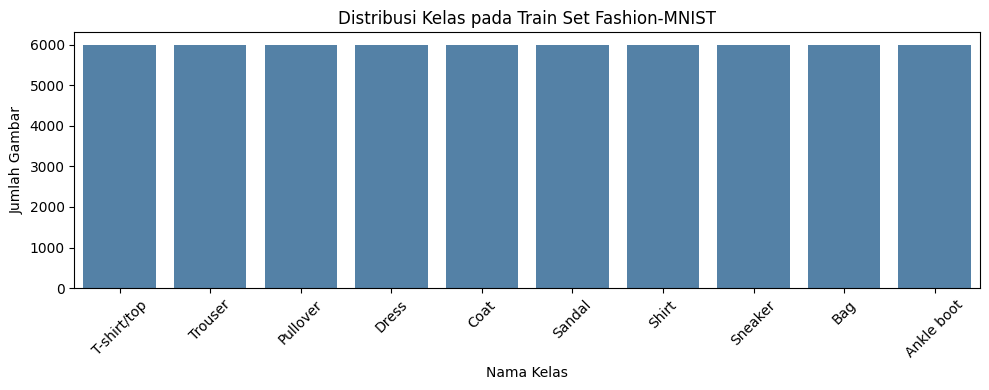

In [7]:
class_counts = train_df["label"].value_counts().sort_index()

plt.figure(figsize=(10, 4))
sns.barplot(x=[label_map[i] for i in class_counts.index], y=class_counts.values, color="steelblue")
plt.title("Distribusi Kelas pada Train Set Fashion-MNIST")
plt.xlabel("Nama Kelas")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretasi:** setiap kelas memiliki jumlah gambar yang sama persis, yaitu **6.000 gambar per kelas** (total 60.000;
test set juga seimbang, 1.000 gambar per kelas). Artinya dataset **balanced**, sehingga tidak perlu teknik khusus seperti
class weight atau resampling, dan *accuracy* cukup representatif sebagai metrik utama (tetap kita lengkapi dengan
precision, recall, dan F1 macro).

### 1.5 Contoh gambar dari setiap kelas (10 kelas × 5 gambar)

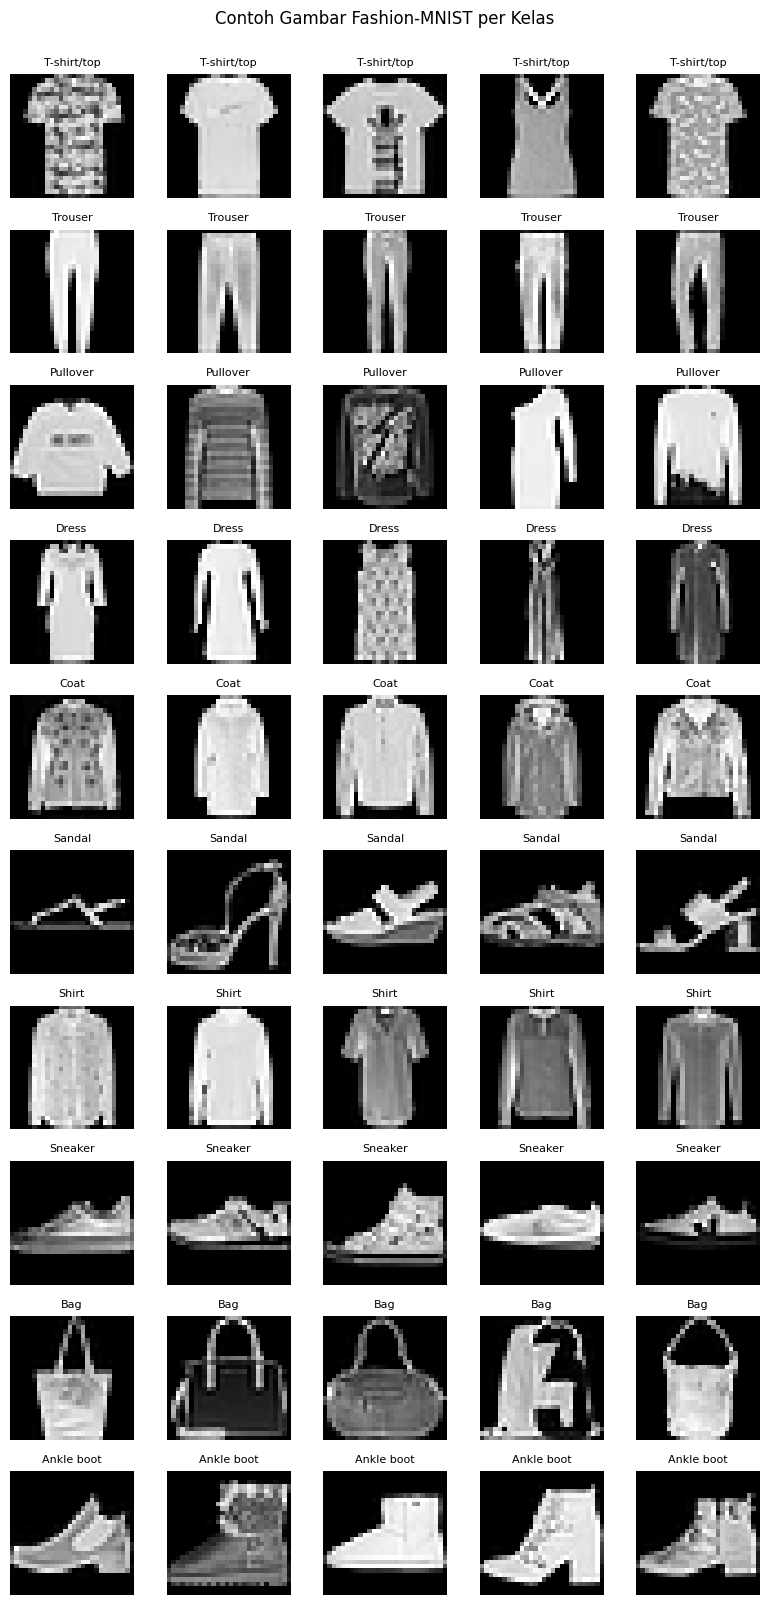

In [8]:
# Ambil data piksel train sebagai array NumPy (masih 0-255, hanya untuk visualisasi)
X_vis = train_df.drop(columns="label").values
y_vis = train_df["label"].values

fig, axes = plt.subplots(10, 5, figsize=(8, 16))
for class_id in range(10):
    # 5 gambar pertama dari kelas tersebut
    idxs = np.where(y_vis == class_id)[0][:5]
    for col, idx in enumerate(idxs):
        ax = axes[class_id, col]
        ax.imshow(X_vis[idx].reshape(28, 28), cmap="gray")   # 784 piksel -> 28x28
        ax.set_title(label_map[class_id], fontsize=8)
        ax.axis("off")
plt.suptitle("Contoh Gambar Fashion-MNIST per Kelas", y=1.0)
plt.tight_layout()
plt.show()

**Kelas yang secara visual terlihat mirip** (berdasarkan grid gambar di atas):

- **T-shirt/top, Shirt, Pullover, dan Coat**: semuanya pakaian atasan dengan badan dan lengan. Perbedaannya halus
  (panjang lengan, ada tidaknya kancing/kerah/resleting), padahal resolusinya hanya 28×28. Kelas **Shirt** terlihat paling
  beragam dan paling mirip dengan T-shirt/top dan Pullover.
- **Sandal, Sneaker, dan Ankle boot**: ketiganya alas kaki dengan siluet horizontal, hanya beda tinggi bagian atas
  dan banyaknya bagian yang terbuka.
- **Dress dan Trouser** (juga Dress dan Coat): siluetnya sama-sama memanjang vertikal, walaupun Trouser punya dua "kaki" yang terpisah.
- **Bag** relatif unik karena bentuknya tidak mirip kelas lain, kecuali sebagian gambar yang tidak ada tali/pegangannya.

Ini hanya dugaan visual; akan kita cek lagi dengan confusion matrix pada bagian evaluasi.

## Exploratory Data Analysis (EDA) tambahan

Rata-rata nilai piksel  : 72.96
Std nilai piksel        : 89.97
Persentase piksel = 0   : 50.18 %  (umumnya latar belakang hitam)


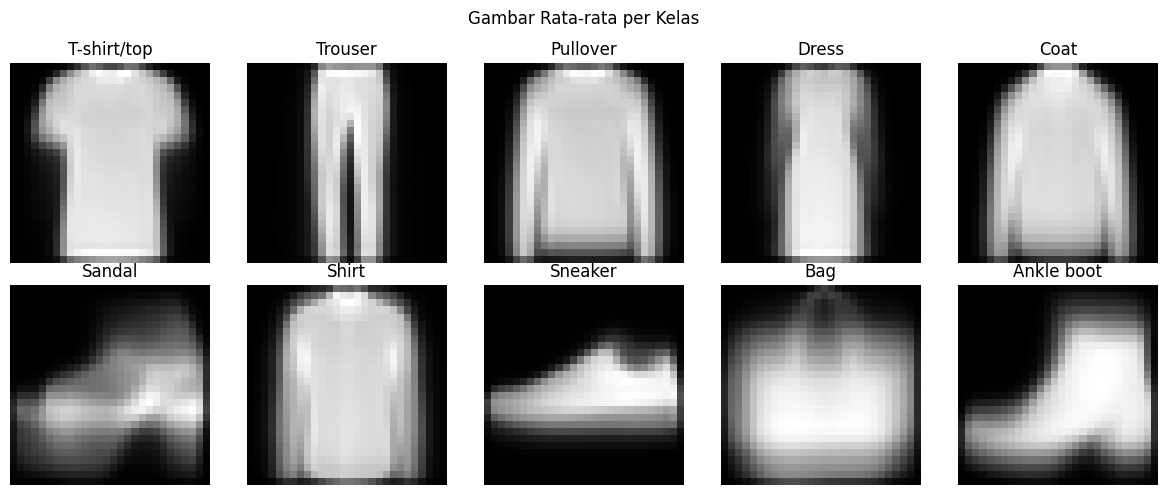

In [9]:
# EDA tambahan 1: statistik piksel keseluruhan
pixels = train_df.drop(columns="label").values
print("Rata-rata nilai piksel  :", round(pixels.mean(), 2))
print("Std nilai piksel        :", round(pixels.std(), 2))
print("Persentase piksel = 0   :", round((pixels == 0).mean() * 100, 2), "%  (umumnya latar belakang hitam)")

# EDA tambahan 2: "gambar rata-rata" tiap kelas
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flatten()):
    mean_img = pixels[y_vis == class_id].mean(axis=0).reshape(28, 28)
    ax.imshow(mean_img, cmap="gray")
    ax.set_title(label_map[class_id])
    ax.axis("off")
plt.suptitle("Gambar Rata-rata per Kelas")
plt.tight_layout()
plt.show()

**Catatan EDA:** sekitar separuh piksel (±50%) bernilai 0 (latar hitam), dan objek selalu berada di tengah gambar dengan ukuran
yang sudah diseragamkan. Gambar rata-rata memperlihatkan bahwa Trouser, Sneaker, dan Ankle boot punya siluet rata-rata yang jelas,
sedangkan Sandal dan Bag tampak kabur karena bentuk antar-gambarnya sangat bervariasi. Kelas atasan (T-shirt/top, Pullover, Coat, Shirt)
bentuk rata-ratanya mirip satu sama lain.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

### 2.1 Memisahkan fitur (piksel) dan label

In [10]:
# Kolom "label" = target (y), 784 kolom lainnya = fitur piksel (X)
X_train_full = train_df.drop(columns="label").values.astype("float32")
y_train_full = train_df["label"].values
X_test = test_df.drop(columns="label").values.astype("float32")
y_test = test_df["label"].values

print("X_train_full:", X_train_full.shape, "| y_train_full:", y_train_full.shape)
print("X_test      :", X_test.shape,       "| y_test      :", y_test.shape)

X_train_full: (60000, 784) | y_train_full: (60000,)
X_test      : (10000, 784) | y_test      : (10000,)


### 2.2 Normalisasi piksel (0-255 menjadi 0-1)

In [11]:
# Normalisasi dilakukan SEKALI saja di sini. Pembagi 255 adalah konstanta (bukan statistik data),
# jadi tidak menyebabkan data leakage antara train dan test.
X_train_full = X_train_full / 255.0
X_test = X_test / 255.0

print("Rentang X_train_full:", X_train_full.min(), "-", X_train_full.max())
print("Rentang X_test      :", X_test.min(), "-", X_test.max())

Rentang X_train_full: 0.0 - 1.0
Rentang X_test      : 0.0 - 1.0


### 2.3 Membagi train dan validation (90:10, stratify)

In [12]:
# stratify=y agar proporsi tiap kelas di train dan validation sama.
# Test set (file CSV terpisah) TIDAK disentuh sampai evaluasi akhir.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.1, stratify=y_train_full, random_state=42
)

print("Train     :", X_train.shape, y_train.shape)
print("Validation:", X_val.shape,   y_val.shape)
print("Test      :", X_test.shape,  y_test.shape)
print("\nJumlah per kelas di validation:", np.bincount(y_val))   # seharusnya 600 per kelas

Train     : (54000, 784) (54000,)
Validation: (6000, 784) (6000,)
Test      : (10000, 784) (10000,)

Jumlah per kelas di validation: [600 600 600 600 600 600 600 600 600 600]


### 2.4 Konversi ke tensor PyTorch dan DataLoader

**Mengapa gambar perlu dimensi channel `(N, 1, 28, 28)`?** Layer `nn.Conv2d` di PyTorch mengharapkan input
berbentuk `(batch, channel, tinggi, lebar)`. Gambar grayscale hanya punya 1 channel (gambar berwarna RGB punya 3),
tetapi dimensi channel itu tetap harus ada secara eksplisit supaya kernel konvolusi tahu berapa channel input yang diproses
(`in_channels=1` pada Conv2d pertama).

- **ANN** memakai tensor yang sama `(N, 1, 28, 28)`, lalu `nn.Flatten()` di dalam model mengubahnya menjadi `(N, 784)`.
- **CNN** langsung memakai `(N, 1, 28, 28)` supaya struktur 2D gambar (tetangga piksel) tetap terjaga.
- Label harus `torch.long` karena dipakai `nn.CrossEntropyLoss` sebagai indeks kelas.

In [13]:
def to_image_tensor(X):
    """Array (N, 784) -> tensor float32 berbentuk (N, 1, 28, 28)."""
    return torch.tensor(X, dtype=torch.float32).reshape(-1, 1, 28, 28)

def to_label_tensor(y):
    """Array label -> tensor long (wajib untuk CrossEntropyLoss)."""
    return torch.tensor(y, dtype=torch.long)

X_train_t, y_train_t = to_image_tensor(X_train), to_label_tensor(y_train)
X_val_t,   y_val_t   = to_image_tensor(X_val),   to_label_tensor(y_val)
X_test_t,  y_test_t  = to_image_tensor(X_test),  to_label_tensor(y_test)

print("X_train_t:", X_train_t.shape, X_train_t.dtype)   # (54000, 1, 28, 28) float32
print("y_train_t:", y_train_t.shape, y_train_t.dtype)   # (54000,) int64

BATCH_SIZE = 128

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)   # hanya train yang di-shuffle
val_loader   = DataLoader(TensorDataset(X_val_t,   y_val_t),   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test_t,  y_test_t),  batch_size=BATCH_SIZE, shuffle=False)

# Catatan: data tetap di CPU. Tiap batch dipindahkan ke device di dalam training loop (x.to(device)).
print("Jumlah batch -> train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

X_train_t: torch.Size([54000, 1, 28, 28]) torch.float32
y_train_t: torch.Size([54000]) torch.int64
Jumlah batch -> train: 422 | val: 47 | test: 79


# 3. Eksperimen Model

### Konfigurasi dan fungsi bersama (dipakai ketiga model)

Agar perbandingan adil, ketiga model memakai pengaturan yang **sama persis**:
`nn.CrossEntropyLoss`, optimizer **Adam**, learning rate **0.001**, batch size **128**, **12 epoch**, dan seed yang sama.
Training loop dibuat sebagai fungsi `train_model()` sehingga tidak perlu ditulis ulang untuk 3.2 dan 3.3.

In [14]:
LEARNING_RATE = 0.001
EPOCHS = 12

def count_parameters(model):
    """Jumlah seluruh parameter yang dapat dilatih."""
    return sum(p.numel() for p in model.parameters())

def evaluate(model, loader, criterion):
    """Hitung rata-rata loss dan accuracy pada sebuah DataLoader (mode evaluasi, tanpa gradient)."""
    model.eval()                       # matikan Dropout, BatchNorm pakai statistik running
    total_loss, total_correct, total_samples = 0.0, 0, 0
    with torch.no_grad():              # tidak perlu menghitung gradient saat evaluasi
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)
            total_loss += loss.item() * x.size(0)                       # dikali ukuran batch -> jumlah loss
            total_correct += (logits.argmax(dim=1) == y).sum().item()
            total_samples += x.size(0)
    return total_loss / total_samples, total_correct / total_samples

def train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE):
    """Training loop yang dipakai ulang untuk ANN, CNN, dan CNN+BN+Dropout. Mengembalikan history."""
    criterion = nn.CrossEntropyLoss()                    # sudah termasuk Softmax di dalamnya
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()                                    # mode training (Dropout aktif, BatchNorm update statistik)
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)            # pindahkan batch ke device yang sama dengan model
            logits = model(x)                            # 1. forward propagation
            loss = criterion(logits, y)                  # 2. hitung loss
            optimizer.zero_grad()                        # 3. kosongkan gradient batch sebelumnya
            loss.backward()                              # 4. backpropagation
            optimizer.step()                             # 5. update bobot

        # Akhir epoch: hitung loss & accuracy train dan validation dengan mode evaluasi
        train_loss, train_acc = evaluate(model, train_loader, criterion)
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss);     history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1:2d}/{epochs} | "
              f"train loss {train_loss:.4f}, acc {train_acc:.4f} | "
              f"val loss {val_loss:.4f}, acc {val_acc:.4f}")
    return history

def plot_learning_curve(history, title):
    """Dua grafik: loss (kiri) dan accuracy (kanan), train vs validation."""
    epochs_range = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs_range, history["train_loss"], marker="o", label="Train loss")
    axes[0].plot(epochs_range, history["val_loss"],   marker="o", label="Validation loss")
    axes[0].set_title(f"{title} - Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

    axes[1].plot(epochs_range, history["train_acc"], marker="o", label="Train accuracy")
    axes[1].plot(epochs_range, history["val_acc"],   marker="o", label="Validation accuracy")
    axes[1].set_title(f"{title} - Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()

    plt.tight_layout()
    plt.show()

def predict(model, loader):
    """Prediksi kelas untuk seluruh isi DataLoader -> NumPy array berisi label prediksi."""
    model.eval()
    all_preds = []
    with torch.no_grad():
        for x, _ in loader:
            logits = model(x.to(device))
            all_preds.append(logits.argmax(dim=1).cpu())   # kelas dengan logit terbesar
    return torch.cat(all_preds).numpy()

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

**Fungsi tiap bagian:**
- `nn.Flatten()`: mengubah `(N, 1, 28, 28)` menjadi `(N, 784)`. Konsekuensinya, **susunan 2D gambar hilang**; ANN memperlakukan 784 piksel sebagai fitur yang berdiri sendiri.
- `nn.Linear(784, 256)` dan `nn.Linear(256, 128)`: *fully connected layer* yang mempelajari kombinasi dari seluruh piksel.
- `nn.ReLU()`: fungsi aktivasi non-linear. Tanpa ini, tumpukan Linear hanya setara satu Linear.
- `nn.Linear(128, 10)`: layer output, 10 neuron = 10 kelas. Outputnya berupa *logits* (belum probabilitas); Softmax dihitung di dalam `CrossEntropyLoss`.

In [15]:
class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),            # (N, 1, 28, 28) -> (N, 784)
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10),      # 10 kelas, tanpa Softmax
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)                # seed sama sebelum membuat tiap model (inisialisasi bobot reproducible)
ann_model = ANN().to(device)
print(ann_model)
print("Jumlah parameter ANN:", count_parameters(ann_model))
# Hitung manual: (784*256+256) + (256*128+128) + (128*10+10) = 200.960 + 32.896 + 1.290 = 235.146

ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter ANN: 235146


In [16]:
# Training ANN (fungsi train_model dipakai ulang untuk model berikutnya)
torch.manual_seed(42)
ann_history = train_model(ann_model, train_loader, val_loader)

Epoch  1/12 | train loss 0.4410, acc 0.8483 | val loss 0.4535, acc 0.8417
Epoch  2/12 | train loss 0.3686, acc 0.8666 | val loss 0.3914, acc 0.8580
Epoch  3/12 | train loss 0.3243, acc 0.8822 | val loss 0.3600, acc 0.8707
Epoch  4/12 | train loss 0.3087, acc 0.8879 | val loss 0.3559, acc 0.8730
Epoch  5/12 | train loss 0.3044, acc 0.8870 | val loss 0.3536, acc 0.8687
Epoch  6/12 | train loss 0.2748, acc 0.8976 | val loss 0.3349, acc 0.8790
Epoch  7/12 | train loss 0.2598, acc 0.9061 | val loss 0.3197, acc 0.8838
Epoch  8/12 | train loss 0.2428, acc 0.9105 | val loss 0.3198, acc 0.8838
Epoch  9/12 | train loss 0.2346, acc 0.9144 | val loss 0.3101, acc 0.8870
Epoch 10/12 | train loss 0.2346, acc 0.9119 | val loss 0.3140, acc 0.8818
Epoch 11/12 | train loss 0.2291, acc 0.9136 | val loss 0.3186, acc 0.8820
Epoch 12/12 | train loss 0.2086, acc 0.9224 | val loss 0.3076, acc 0.8910


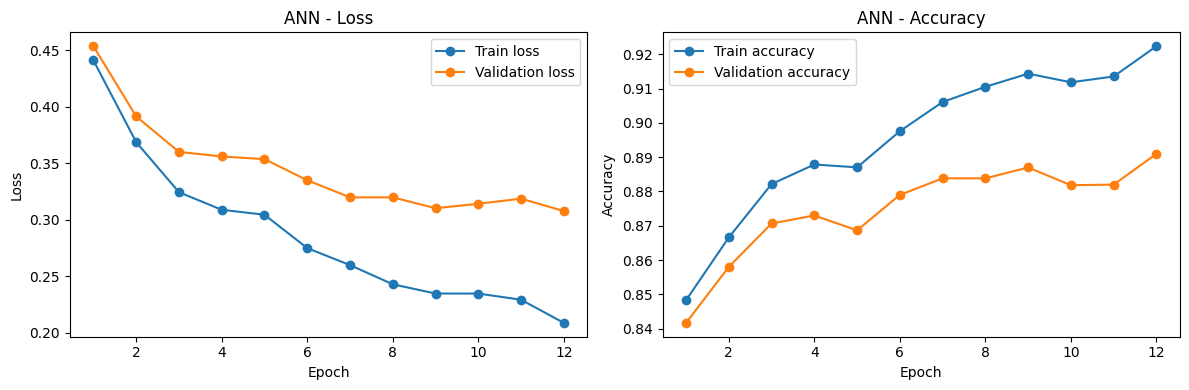

In [17]:
plot_learning_curve(ann_history, "ANN")

**Interpretasi learning curve ANN:** ▢ ISI setelah run. Lihat apakah train loss terus turun, apakah validation loss mulai naik
(tanda overfitting), dan berapa selisih train accuracy vs validation accuracy di epoch terakhir.

In [18]:
# Prediksi pada test set -> NumPy array label
ann_test_pred = predict(ann_model, test_loader)
print("Bentuk prediksi ANN:", ann_test_pred.shape, "| contoh 10 prediksi pertama:", ann_test_pred[:10])

Bentuk prediksi ANN: (10000,) | contoh 10 prediksi pertama: [0 1 2 2 3 6 8 3 5 0]


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

**Perhitungan dimensi manual** dengan rumus `Output = (W - K + 2P) / S + 1`
(W = ukuran input, K = kernel, P = padding, S = stride). Pada `MaxPool2d(2)`, stride otomatis = 2 dan padding = 0.

| Layer | Perhitungan | Output (C × H × W) |
|---|---|---|
| Input | | 1 × 28 × 28 |
| Conv2d(1, 32, K=3, P=1, S=1) | (28 − 3 + 2·1)/1 + 1 = **28** | 32 × 28 × 28 |
| ReLU | tidak mengubah ukuran | 32 × 28 × 28 |
| MaxPool2d(2) | (28 − 2 + 0)/2 + 1 = **14** | 32 × 14 × 14 |
| Conv2d(32, 64, K=3, P=1, S=1) | (14 − 3 + 2·1)/1 + 1 = **14** | 64 × 14 × 14 |
| ReLU | tidak mengubah ukuran | 64 × 14 × 14 |
| MaxPool2d(2) | (14 − 2 + 0)/2 + 1 = **7** | 64 × 7 × 7 |
| Flatten | 64 × 7 × 7 = **3136** | 3136 |

Dengan `padding=1` dan kernel 3×3, ukuran spasial **tidak berubah** setelah konvolusi; yang mengecilkan ukuran hanya pooling (28 → 14 → 7).
Jumlah channel ditentukan oleh jumlah filter (32, lalu 64). Karena itu input `nn.Linear` pertama harus **`64 × 7 × 7 = 3136`**:
setelah Flatten, semua nilai dari feature map (channel × tinggi × lebar) menjadi satu vektor, dan jumlah elemennya harus sama persis dengan `in_features`.

In [19]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Bagian ekstraksi fitur: 2 blok konvolusi
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),   # (1,28,28)  -> (32,28,28)
            nn.ReLU(),
            nn.MaxPool2d(2),                              # (32,28,28) -> (32,14,14)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # (32,14,14) -> (64,14,14)
            nn.ReLU(),
            nn.MaxPool2d(2),                              # (64,14,14) -> (64,7,7)
        )
        # Bagian klasifikasi
        self.classifier = nn.Sequential(
            nn.Flatten(),                                 # (64,7,7) -> 3136
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),                           # 10 kelas, tanpa Softmax
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

torch.manual_seed(42)
cnn_model = SimpleCNN().to(device)
print(cnn_model)
print("Jumlah parameter CNN sederhana:", count_parameters(cnn_model))
# Hitung manual: conv1 (1*32*3*3+32=320) + conv2 (32*64*3*3+64=18.496) + fc1 (3136*128+128=401.536) + fc2 (128*10+10=1.290) = 421.642

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter CNN sederhana: 421642


In [20]:
# Verifikasi perhitungan dimensi dengan tensor dummy: lewatkan satu layer demi satu layer
dummy = torch.zeros(1, 1, 28, 28).to(device)
print("Input        :", tuple(dummy.shape))
out = dummy
for layer in cnn_model.features:
    out = layer(out)
    print(f"{layer.__class__.__name__:10s} -> {tuple(out.shape)}")
print("Output bagian konvolusi:", tuple(out.shape), "-> setelah Flatten:", out.flatten(1).shape[1], "(harus 3136 = 64*7*7)")

Input        : (1, 1, 28, 28)
Conv2d     -> (1, 32, 28, 28)
ReLU       -> (1, 32, 28, 28)
MaxPool2d  -> (1, 32, 14, 14)
Conv2d     -> (1, 64, 14, 14)
ReLU       -> (1, 64, 14, 14)
MaxPool2d  -> (1, 64, 7, 7)
Output bagian konvolusi: (1, 64, 7, 7) -> setelah Flatten: 3136 (harus 3136 = 64*7*7)


In [21]:
# Training dengan pengaturan yang sama seperti ANN
torch.manual_seed(42)
cnn_history = train_model(cnn_model, train_loader, val_loader)

Epoch  1/12 | train loss 0.3762, acc 0.8701 | val loss 0.3840, acc 0.8743
Epoch  2/12 | train loss 0.3018, acc 0.8911 | val loss 0.3217, acc 0.8895
Epoch  3/12 | train loss 0.2598, acc 0.9060 | val loss 0.2842, acc 0.8955
Epoch  4/12 | train loss 0.2355, acc 0.9149 | val loss 0.2736, acc 0.9043
Epoch  5/12 | train loss 0.2196, acc 0.9205 | val loss 0.2586, acc 0.9028
Epoch  6/12 | train loss 0.1997, acc 0.9277 | val loss 0.2485, acc 0.9088
Epoch  7/12 | train loss 0.1880, acc 0.9304 | val loss 0.2448, acc 0.9135
Epoch  8/12 | train loss 0.1661, acc 0.9396 | val loss 0.2331, acc 0.9155
Epoch  9/12 | train loss 0.1501, acc 0.9463 | val loss 0.2242, acc 0.9172
Epoch 10/12 | train loss 0.1426, acc 0.9489 | val loss 0.2306, acc 0.9175
Epoch 11/12 | train loss 0.1288, acc 0.9535 | val loss 0.2240, acc 0.9200
Epoch 12/12 | train loss 0.1188, acc 0.9564 | val loss 0.2426, acc 0.9183


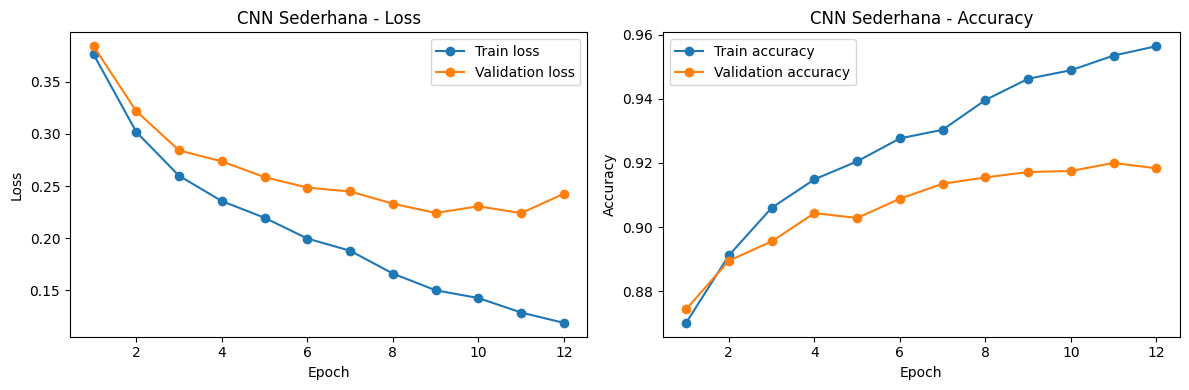

In [22]:
plot_learning_curve(cnn_history, "CNN Sederhana")

**Perbandingan proses belajar CNN vs ANN:** ▢ ISI setelah run. Bandingkan validation accuracy di epoch 1 dan epoch terakhir,
serta selisih train–validation, antara ANN dan CNN sederhana.

In [23]:
cnn_test_pred = predict(cnn_model, test_loader)
print("Bentuk prediksi CNN sederhana:", cnn_test_pred.shape)

Bentuk prediksi CNN sederhana: (10000,)


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

**Penjelasan singkat:**
- **Batch Normalization (`nn.BatchNorm2d`)**: menormalkan output tiap channel (rata-rata ≈ 0, varians ≈ 1) berdasarkan statistik mini-batch,
  lalu diskalakan dan digeser dengan parameter yang dipelajari. Efeknya, distribusi input antar-layer lebih stabil sehingga training
  biasanya lebih cepat dan stabil, dan memberi sedikit efek regularisasi.
- **Dropout (`nn.Dropout(p)`)**: saat training, secara acak "mematikan" sebagian neuron (di sini 30%) sehingga model tidak terlalu bergantung pada neuron tertentu.
  Tujuannya mengurangi overfitting. Dropout ditaruh sebelum layer output, yaitu setelah layer Linear 128 neuron yang paling banyak parameternya.
- **Mengapa dipakai di sini?** CNN sederhana punya layer Linear besar (3136 → 128), yang rawan overfitting. BatchNorm membantu optimasi,
  Dropout membantu generalisasi. Kita bandingkan apakah benar membantu pada data ini.
- **Mode train vs eval:** saat `model.train()` Dropout aktif dan BatchNorm memakai statistik batch; saat `model.eval()` Dropout dimatikan dan BatchNorm memakai statistik
  rata-rata yang sudah dipelajari. Fungsi `train_model()` dan `evaluate()` kita sudah memanggil keduanya di tempat yang tepat.

In [24]:
class CNNBatchNormDropout(nn.Module):
    def __init__(self, dropout_p=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),          # jumlah channel = output Conv2d sebelumnya
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(dropout_p),       # Dropout sebelum layer output
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

torch.manual_seed(42)
cnn_bn_model = CNNBatchNormDropout(dropout_p=0.3).to(device)
print(cnn_bn_model)
print("Jumlah parameter CNN + BN + Dropout:", count_parameters(cnn_bn_model))
# Hitung manual: 421.642 (CNN sederhana) + BN1 (32*2=64) + BN2 (64*2=128) = 421.834
# (gamma & beta dihitung sebagai parameter; running mean/var adalah buffer, bukan parameter. Dropout tidak punya parameter.)

CNNBatchNormDropout(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter CNN + BN + Dropout: 421834


In [25]:
# Training dengan pengaturan yang sama seperti 3.2
torch.manual_seed(42)
cnn_bn_history = train_model(cnn_bn_model, train_loader, val_loader)

Epoch  1/12 | train loss 0.3012, acc 0.8876 | val loss 0.3205, acc 0.8835
Epoch  2/12 | train loss 0.2344, acc 0.9108 | val loss 0.2679, acc 0.9013
Epoch  3/12 | train loss 0.2021, acc 0.9248 | val loss 0.2481, acc 0.9085
Epoch  4/12 | train loss 0.1786, acc 0.9329 | val loss 0.2365, acc 0.9155
Epoch  5/12 | train loss 0.1678, acc 0.9389 | val loss 0.2333, acc 0.9170
Epoch  6/12 | train loss 0.1464, acc 0.9469 | val loss 0.2201, acc 0.9173
Epoch  7/12 | train loss 0.1462, acc 0.9444 | val loss 0.2351, acc 0.9113
Epoch  8/12 | train loss 0.1267, acc 0.9531 | val loss 0.2386, acc 0.9165
Epoch  9/12 | train loss 0.1181, acc 0.9552 | val loss 0.2330, acc 0.9180
Epoch 10/12 | train loss 0.0958, acc 0.9660 | val loss 0.2333, acc 0.9202
Epoch 11/12 | train loss 0.0910, acc 0.9667 | val loss 0.2361, acc 0.9203
Epoch 12/12 | train loss 0.0985, acc 0.9650 | val loss 0.2361, acc 0.9168


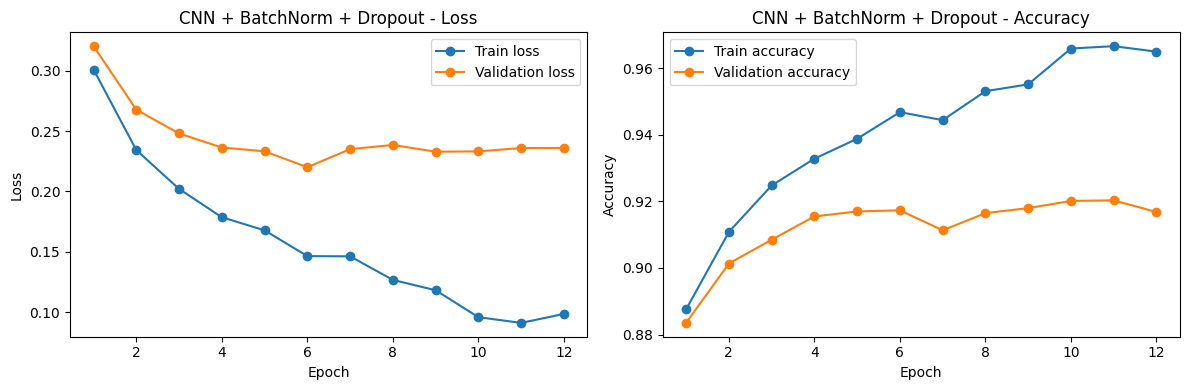

In [26]:
plot_learning_curve(cnn_bn_history, "CNN + BatchNorm + Dropout")

**Perbandingan dengan CNN sederhana:** ▢ ISI setelah run. Bandingkan selisih train–validation, kestabilan validation loss, dan
kecepatan naiknya accuracy pada kedua CNN.

In [27]:
cnn_bn_test_pred = predict(cnn_bn_model, test_loader)
print("Bentuk prediksi CNN+BN+Dropout:", cnn_bn_test_pred.shape)

Bentuk prediksi CNN+BN+Dropout: (10000,)


# 4. Evaluasi Model

### 4.1 Tabel perbandingan

Metrik dihitung pada **test set** (evaluasi akhir). Kolom *Val Accuracy (epoch terakhir)* diambil dari history training dan
dipakai untuk **memilih model terbaik**, sesuai ketentuan bahwa pemilihan model tidak boleh memakai test set.

In [28]:
models = {
    "ANN": ann_model,
    "CNN Sederhana": cnn_model,
    "CNN + BatchNorm + Dropout": cnn_bn_model,
}
histories = {
    "ANN": ann_history,
    "CNN Sederhana": cnn_history,
    "CNN + BatchNorm + Dropout": cnn_bn_history,
}
test_preds = {
    "ANN": ann_test_pred,
    "CNN Sederhana": cnn_test_pred,
    "CNN + BatchNorm + Dropout": cnn_bn_test_pred,
}

rows = []
for name in models:
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, test_preds[name], average="macro", zero_division=0)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, test_preds[name]),
        "Precision (macro)": prec,
        "Recall (macro)": rec,
        "F1-Score (macro)": f1,
        "Jumlah Parameter": count_parameters(models[name]),
        "Val Accuracy (epoch terakhir)": histories[name]["val_acc"][-1],
    })
results_df = pd.DataFrame(rows).set_index("Model")
display(results_df.style.format({
    "Accuracy": "{:.4f}", "Precision (macro)": "{:.4f}", "Recall (macro)": "{:.4f}",
    "F1-Score (macro)": "{:.4f}", "Jumlah Parameter": "{:,}", "Val Accuracy (epoch terakhir)": "{:.4f}",
}))

# Model terbaik dipilih berdasarkan VALIDATION accuracy, bukan test
best_model_name = results_df["Val Accuracy (epoch terakhir)"].idxmax()
best_model = models[best_model_name]
best_pred = test_preds[best_model_name]
print("Model terbaik (berdasarkan validation accuracy):", best_model_name)

# Untuk feature map: butuh model dengan layer konvolusi -> pilih CNN dengan validation accuracy terbaik
cnn_names = ["CNN Sederhana", "CNN + BatchNorm + Dropout"]
best_cnn_name = max(cnn_names, key=lambda n: histories[n]["val_acc"][-1])
best_cnn = models[best_cnn_name]
print("CNN terbaik untuk visualisasi feature map     :", best_cnn_name)

,Accuracy,Precision (macro),Recall (macro),F1-Score (macro),Jumlah Parameter,Val Accuracy (epoch terakhir)
Model,,,,,,
ANN,0.8942,0.8938,0.8942,0.8935,"235,146",0.8910
CNN Sederhana,0.9252,0.9253,0.9252,0.9246,"421,642",0.9183
CNN + BatchNorm + Dropout,0.9262,0.9279,0.9262,0.9262,"421,834",0.9168


Model terbaik (berdasarkan validation accuracy): CNN Sederhana
CNN terbaik untuk visualisasi feature map     : CNN Sederhana


**Interpretasi tabel:** ▢ ISI setelah run. Sebutkan model dengan accuracy/F1 tertinggi, selisihnya dengan model lain,
dan apakah urutan model berdasarkan *validation* sama dengan urutan berdasarkan *test*.

### 4.2 Classification report (model terbaik)

In [29]:
print(f"Classification report - {best_model_name}\n")
print(classification_report(y_test, best_pred, target_names=class_names, digits=4))

Classification report - CNN Sederhana

              precision    recall  f1-score   support

 T-shirt/top     0.8567    0.8730    0.8648      1000
     Trouser     0.9861    0.9910    0.9885      1000
    Pullover     0.8444    0.9280    0.8842      1000
       Dress     0.9442    0.9300    0.9370      1000
        Coat     0.8795    0.9050    0.8921      1000
      Sandal     0.9939    0.9700    0.9818      1000
       Shirt     0.8470    0.7310    0.7848      1000
     Sneaker     0.9501    0.9710    0.9604      1000
         Bag     0.9880    0.9850    0.9865      1000
  Ankle boot     0.9632    0.9680    0.9656      1000

    accuracy                         0.9252     10000
   macro avg     0.9253    0.9252    0.9246     10000
weighted avg     0.9253    0.9252    0.9246     10000



**Cara membaca:**
- **Precision** kelas X = dari semua gambar yang *diprediksi* X, berapa persen yang benar-benar X. Precision rendah berarti banyak kelas lain yang salah dikira X.
- **Recall** kelas X = dari semua gambar yang *sebenarnya* X, berapa persen yang berhasil ditemukan. Recall rendah berarti banyak gambar X yang dikira kelas lain.
- **F1-score** = rata-rata harmonik precision dan recall; tinggi hanya jika keduanya tinggi.
- **support** = jumlah gambar kelas tersebut di test set (1.000 per kelas), **macro avg** = rata-rata biasa antar-kelas.

▢ ISI setelah run: sebutkan kelas dengan F1 tertinggi dan terendah.

### 4.3 Confusion matrix (model terbaik)

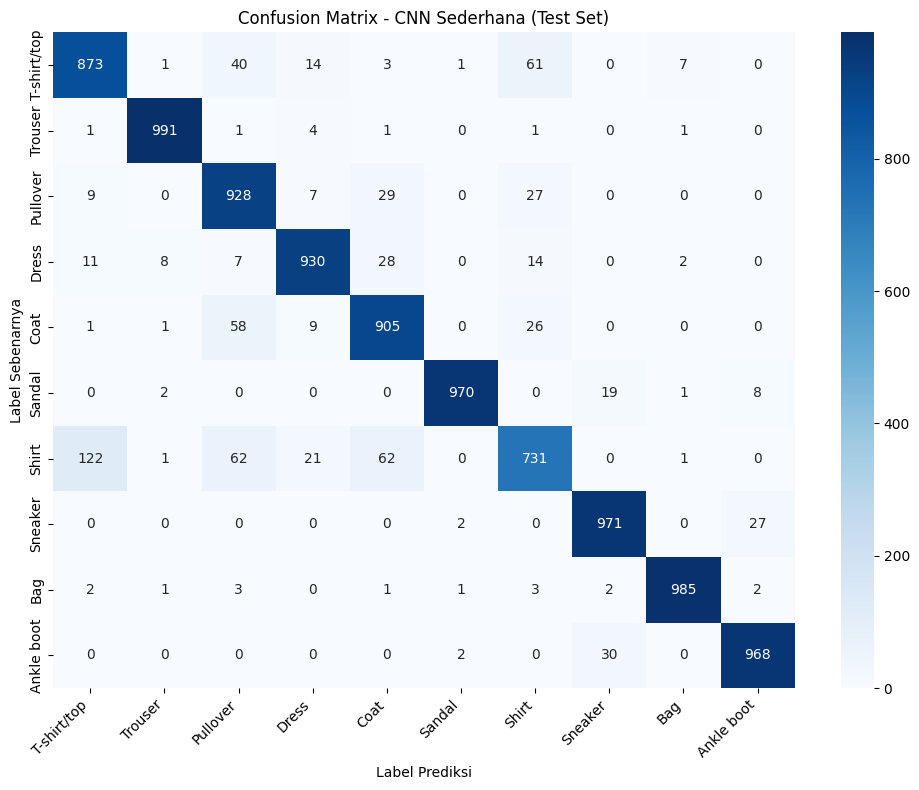

5 kesalahan terbanyak (label sebenarnya -> diprediksi sebagai):
  Shirt        -> T-shirt/top  : 122 gambar
  Shirt        -> Coat         : 62 gambar
  Shirt        -> Pullover     : 62 gambar
  T-shirt/top  -> Shirt        : 61 gambar
  Coat         -> Pullover     : 58 gambar


In [30]:
cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix - {best_model_name} (Test Set)")
plt.xlabel("Label Prediksi")
plt.ylabel("Label Sebenarnya")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Cari pasangan kelas yang paling sering tertukar (nilai di luar diagonal)
errors = cm.copy()
np.fill_diagonal(errors, 0)
top_pairs = np.dstack(np.unravel_index(np.argsort(errors.ravel())[::-1], errors.shape))[0][:5]
print("5 kesalahan terbanyak (label sebenarnya -> diprediksi sebagai):")
for true_id, pred_id in top_pairs:
    print(f"  {class_names[true_id]:12s} -> {class_names[pred_id]:12s} : {errors[true_id, pred_id]} gambar")

**Pasangan kelas yang paling sering tertukar:** ▢ ISI dari output di atas.
Hubungkan dengan pengamatan visual di bagian 1.5 (misalnya Shirt vs T-shirt/top, Pullover vs Coat): atasan dengan siluet yang mirip dan perbedaan detail halus
(kerah, kancing, panjang lengan) yang sulit terlihat pada resolusi 28×28.

### 4.4 Contoh gambar yang salah diklasifikasikan (model terbaik)

Jumlah salah klasifikasi: 748 dari 10000 gambar test


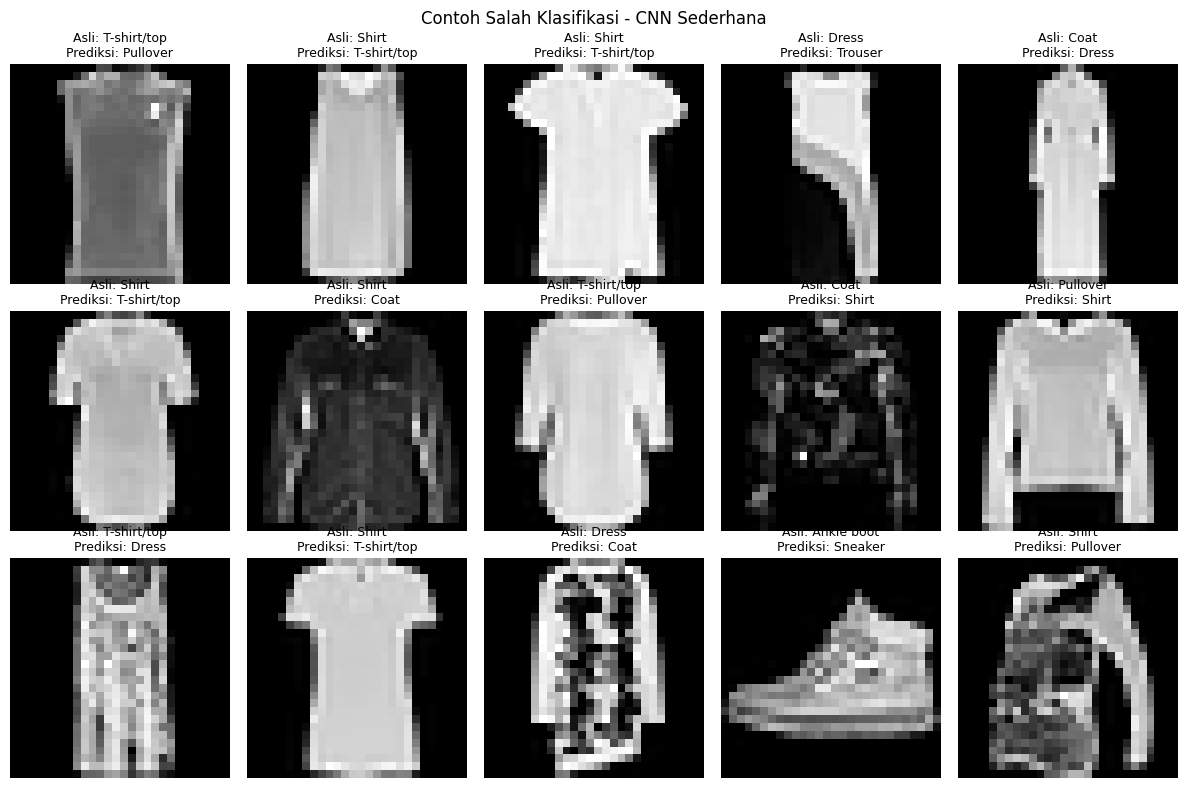

In [31]:
wrong_idx = np.where(best_pred != y_test)[0]
print(f"Jumlah salah klasifikasi: {len(wrong_idx)} dari {len(y_test)} gambar test")

# Ambil 15 contoh acak (seed tetap supaya sama setiap dijalankan)
rng = np.random.RandomState(42)
sample_idx = rng.choice(wrong_idx, size=min(15, len(wrong_idx)), replace=False)

fig, axes = plt.subplots(3, 5, figsize=(12, 8))
for ax, idx in zip(axes.flatten(), sample_idx):
    ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"Asli: {label_map[y_test[idx]]}\nPrediksi: {label_map[best_pred[idx]]}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Contoh Salah Klasifikasi - {best_model_name}")
plt.tight_layout()
plt.show()

**Kemungkinan penyebab kesalahan:** ▢ ISI setelah melihat gambar yang tampil (gambar yang dipilih acak, jadi amati sendiri).
Hal yang biasa dicek: apakah bentuk siluetnya memang mirip kelas yang diprediksi, apakah detail pembeda (kerah, tali, lengan) hilang, atau apakah gambarnya ambigu bahkan bagi manusia.

### 4.5 Visualisasi feature map (layer konvolusi pertama)

Bentuk feature map: (32, 28, 28)


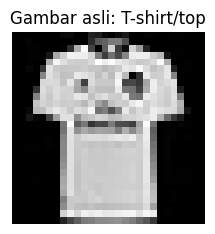

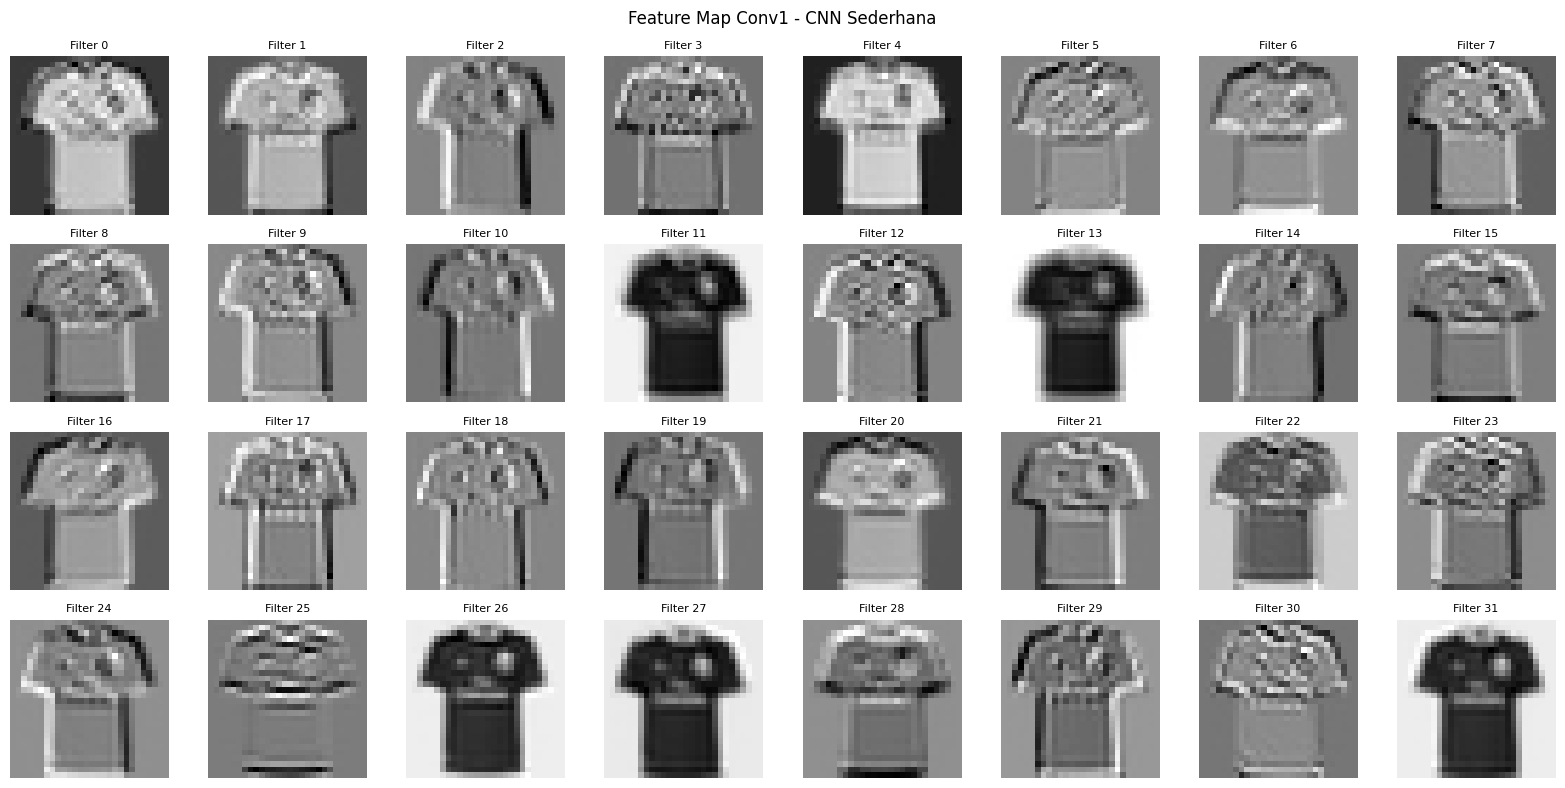

In [32]:
# ANN tidak punya layer konvolusi, jadi feature map diambil dari CNN terbaik (best_cnn) berdasarkan validation accuracy.
# (Model terbaik keseluruhan untuk disimpan/deployment bisa berbeda dengan model untuk visualisasi ini.)
sample_id = 0                                   # indeks gambar contoh di test set
x_sample = X_test_t[sample_id:sample_id + 1].to(device)   # bentuk (1, 1, 28, 28)

best_cnn.eval()
with torch.no_grad():
    fmap = best_cnn.features[0](x_sample)       # features[0] = Conv2d pertama -> (1, 32, 28, 28)
fmap = fmap.detach().cpu().numpy()[0]           # (32, 28, 28)
print("Bentuk feature map:", fmap.shape)

# Gambar asli
plt.figure(figsize=(2.5, 2.5))
plt.imshow(X_test[sample_id].reshape(28, 28), cmap="gray")
plt.title(f"Gambar asli: {label_map[y_test[sample_id]]}")
plt.axis("off")
plt.show()

# 32 feature map dalam grid 4 x 8
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(fmap[i], cmap="gray")
    ax.set_title(f"Filter {i}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Feature Map Conv1 - {best_cnn_name}")
plt.tight_layout()
plt.show()

**Pola yang ditangkap filter:** ▢ ISI setelah melihat gambar. Panduan pengamatan: sebagian feature map biasanya menyorot **tepi/kontur** objek
(misalnya batas lengan atau badan), sebagian menonjolkan **area terang/gelap** (isi objek vs latar), dan ada yang tampak
hampir seragam atau kurang informatif. Cukup deskripsikan yang benar-benar terlihat; jangan mengklaim fungsi filter yang tidak tampak jelas dari gambar.

### 4.6 Menyimpan model terbaik

In [33]:
# Simpan bobot (state_dict) model terbaik berdasarkan validation accuracy
torch.save(best_model.state_dict(), "model.pth")
print(f"Model '{best_model_name}' disimpan ke model.pth")
print("Definisi class model (ANN / SimpleCNN / CNNBatchNormDropout) ada di cell di atas.")
print("Untuk tugas Deployment, salin definisi class model terbaik beserta file model.pth ini.")

Model 'CNN Sederhana' disimpan ke model.pth
Definisi class model (ANN / SimpleCNN / CNNBatchNormDropout) ada di cell di atas.
Untuk tugas Deployment, salin definisi class model terbaik beserta file model.pth ini.


In [34]:
# Contoh memuat kembali model: buat arsitektur yang sama, lalu load_state_dict
model_classes = {"ANN": ANN, "CNN Sederhana": SimpleCNN, "CNN + BatchNorm + Dropout": CNNBatchNormDropout}

loaded_model = model_classes[best_model_name]().to(device)
loaded_model.load_state_dict(torch.load("model.pth", map_location=device))
loaded_model.eval()                              # wajib eval() sebelum prediksi

# Cek: model yang dimuat harus memberi prediksi yang sama dengan model asli
loaded_pred = predict(loaded_model, test_loader)
print("Prediksi model yang dimuat identik dengan model asli?", np.array_equal(loaded_pred, best_pred))

# Contoh prediksi satu gambar
img = X_test_t[5:6].to(device)
with torch.no_grad():
    pred_id = loaded_model(img).argmax(dim=1).item()
print(f"Gambar test ke-5 -> prediksi: {label_map[pred_id]} | label asli: {label_map[y_test[5]]}")

Prediksi model yang dimuat identik dengan model asli? True
Gambar test ke-5 -> prediksi: Pullover | label asli: Pullover


# 5. Analisis

**1. Karakteristik dataset (dari EDA).**

Dataset Fashion-MNIST memiliki 60.000 gambar untuk data train dan 10.000 gambar untuk data test. Setiap gambar berukuran 28×28 piksel, berwarna grayscale, dan memiliki 10 kategori pakaian. Jumlah gambar pada setiap kelas seimbang, yaitu 6.000 gambar per kelas pada data train dan 1.000 gambar per kelas pada data test. Tidak ditemukan missing value, sedangkan nilai piksel awal berada pada rentang 0–255. Dari hasil EDA, sekitar 50,18% piksel bernilai 0 atau berwarna hitam, yang sebagian besar merupakan latar belakang gambar. Karena jumlah gambar tiap kelas seimbang, accuracy dapat digunakan sebagai salah satu metrik utama untuk menilai model.

**2. Kelas yang mirip secara visual.**

Beberapa kategori memiliki bentuk yang hampir sama. Contohnya adalah T-shirt/top, Shirt, Pullover, dan Coat yang sama-sama termasuk pakaian atasan. Kategori Sandal, Sneaker, dan Ankle boot juga sama-sama merupakan alas kaki. Kemiripan ini dapat membuat model kesulitan membedakan kelas, terutama karena gambar hanya memiliki resolusi 28×28 piksel. Hasil confusion matrix nantinya menunjukkan bahwa kesalahan paling banyak memang terjadi pada kategori pakaian atasan.

**3. ANN vs CNN sederhana.**

Pada test set, ANN mendapatkan accuracy sebesar 89,42%, sedangkan CNN sederhana mendapatkan accuracy sebesar 92,52%. CNN sederhana lebih tinggi sebesar 3,10 poin persentase. Hasil ini menunjukkan bahwa CNN lebih baik dalam mengklasifikasikan gambar pada eksperimen ini. Salah satu alasannya adalah ANN mengubah gambar menjadi 784 nilai piksel dalam satu deretan (flatten), sedangkan CNN tetap memanfaatkan susunan piksel sebagai gambar dua dimensi.

**4. Mengapa CNN cocok untuk gambar.**

CNN cocok digunakan untuk data gambar karena dapat mempelajari pola yang terbentuk dari hubungan antar-piksel. Pada eksperimen ini, CNN menggunakan filter berukuran 3×3 untuk menangkap pola sederhana seperti tepi, bentuk, dan kontur pakaian. Filter yang sama digunakan pada berbagai bagian gambar, sehingga model tidak perlu mempelajari bobot yang sepenuhnya berbeda untuk setiap posisi piksel. Proses pooling juga membantu memperkecil ukuran fitur sambil mempertahankan informasi penting. Dengan cara ini, CNN dapat mengenali bentuk pakaian dengan lebih baik dibandingkan ANN pada hasil eksperimen ini.

**5. CNN sederhana vs CNN + BatchNorm + Dropout.**

Accuracy test CNN sederhana adalah 92,52%, sedangkan CNN dengan Batch Normalization dan Dropout adalah 92,62%. Model dengan Batch Normalization dan Dropout unggul hanya 0,10 poin persentase, sehingga perbedaannya sangat kecil. Jika dilihat dari validation accuracy pada epoch terakhir, CNN sederhana justru sedikit lebih tinggi, yaitu 91,83%, dibandingkan CNN dengan Batch Normalization dan Dropout sebesar 91,68%. Oleh karena itu, penambahan Batch Normalization dan Dropout belum menunjukkan peningkatan yang besar pada eksperimen ini.

**6. Pengaruh jumlah parameter.**

ANN memiliki 235.146 parameter, CNN sederhana memiliki 421.642 parameter, dan CNN dengan Batch Normalization dan Dropout memiliki 421.834 parameter. CNN memiliki parameter lebih banyak daripada ANN, tetapi jumlah parameter yang lebih banyak tidak selalu berarti model akan memiliki hasil yang lebih baik. Hal ini terlihat dari dua model CNN: jumlah parameter CNN dengan Batch Normalization dan Dropout hanya bertambah 192 parameter, sedangkan hasil accuracy test-nya hanya berbeda 0,10 poin persentase dari CNN sederhana. Jadi, performa model tidak hanya ditentukan oleh jumlah parameter, tetapi juga oleh susunan arsitektur dan cara model mempelajari fitur gambar.

**7. Overfitting / underfitting.**

Ketiga model menunjukkan penurunan train loss dan peningkatan train accuracy selama proses training. Namun, train accuracy pada akhir training lebih tinggi daripada validation accuracy. Selisihnya adalah 3,14 poin persentase pada ANN, 3,81 poin persentase pada CNN sederhana, dan 4,82 poin persentase pada CNN dengan Batch Normalization dan Dropout. Hal ini menunjukkan adanya perbedaan kemampuan model saat menghadapi data latihan dan data validasi. CNN sederhana dan CNN dengan Batch Normalization dan Dropout juga mengalami kenaikan validation loss pada beberapa epoch menjelang akhir training. Kondisi tersebut dapat menjadi tanda awal overfitting, meskipun belum berarti model mengalami overfitting yang sangat berat.

**8. Pengaruh BatchNorm dan Dropout terhadap training.**

Batch Normalization dan Dropout ditambahkan dengan tujuan membantu proses training dan mengurangi overfitting. Pada hasil eksperimen, CNN dengan Batch Normalization dan Dropout memiliki validation accuracy yang cukup baik sejak awal. Nilainya sempat mencapai 92,03% pada epoch ke-11, tetapi turun menjadi 91,68% pada epoch ke-12. Validation loss terendahnya adalah 0,2201 pada epoch ke-6. Walaupun hasil test model ini sedikit lebih tinggi daripada CNN sederhana, jarak train-validation pada epoch terakhir justru lebih besar. Jadi, pada eksperimen ini Batch Normalization dan Dropout memberikan hasil yang cukup baik, tetapi belum terbukti mengurangi jarak antara performa data train dan validation.

**9. Kelas yang paling sering salah.**

Berdasarkan classification report, kelas yang paling mudah dikenali adalah Trouser dengan F1-score 98,85%, sedangkan kelas yang paling sulit dikenali adalah Shirt dengan F1-score 78,48%. Confusion matrix menunjukkan bahwa kesalahan terbanyak adalah Shirt yang diprediksi sebagai T-shirt/top sebanyak 122 gambar. Kesalahan lain yang cukup sering terjadi adalah Shirt diprediksi sebagai Coat atau Pullover. Hasil ini sesuai dengan kemiripan bentuk pakaian atasan yang sudah terlihat pada saat eksplorasi dataset. Dari 10.000 gambar test, model salah mengklasifikasikan 748 gambar.

**10. Model terbaik.**

Berdasarkan aturan pemilihan model pada notebook, yaitu menggunakan validation accuracy pada epoch terakhir, model terbaik adalah CNN sederhana dengan validation accuracy 91,83%. Pada test set, model ini memperoleh accuracy 92,52% dan F1-score macro 92,46%. Walaupun CNN dengan Batch Normalization dan Dropout memiliki accuracy test sedikit lebih tinggi, model tersebut tidak dipilih karena validation accuracy akhirnya lebih rendah. Pemilihan berdasarkan data validasi dilakukan agar test set tetap digunakan sebagai evaluasi akhir, bukan sebagai dasar pemilihan model.

# 6. Kesimpulan dan Saran

**Kesimpulan**

**1. ANN vs CNN:** 

CNN sederhana memberikan hasil lebih baik daripada ANN. Accuracy CNN sederhana sebesar 92,52%, sedangkan ANN sebesar 89,42%, sehingga CNN unggul 3,10 poin persentase. Hal ini karena CNN dapat memanfaatkan susunan piksel dan pola bentuk pada gambar, sedangkan ANN meratakan gambar menjadi 784 nilai piksel sebelum diproses.

**2. CNN sederhana vs CNN + BatchNorm + Dropout:**

Accuracy test CNN sederhana sebesar 92,52%, sedangkan CNN dengan Batch Normalization dan Dropout sebesar 92,62%. Selisihnya hanya 0,10 poin persentase. Pada validation accuracy epoch terakhir, CNN sederhana sedikit lebih tinggi, yaitu 91,83%, dibandingkan CNN dengan Batch Normalization dan Dropout sebesar 91,68%. Dengan demikian, penambahan Batch Normalization dan Dropout belum memberikan peningkatan yang besar pada hasil eksperimen ini.

**3. Model terbaik:** 

Berdasarkan validation accuracy pada epoch terakhir, model yang dipilih adalah CNN sederhana. Model ini memiliki validation accuracy 91,83%, accuracy test 92,52%, dan F1-score macro 92,46%. CNN dengan Batch Normalization dan Dropout memang memperoleh accuracy test 92,62%, tetapi tidak dipilih karena pemilihan model mengikuti hasil validation set, bukan test set.

**4. Arsitektur dan jumlah parameter:** 

ANN memiliki 235.146 parameter, CNN sederhana memiliki 421.642 parameter, sedangkan CNN dengan Batch Normalization dan Dropout memiliki 421.834 parameter. Hasil ini menunjukkan bahwa jumlah parameter yang lebih banyak tidak otomatis membuat model jauh lebih baik. CNN dapat memperoleh hasil lebih baik karena arsitekturnya sesuai untuk mempelajari pola pada gambar.

**5. Kemampuan membedakan 10 kategori:** 

Model cukup baik dalam mengenali kategori Trouser, Bag, dan Sandal, dengan F1-score masing-masing 98,85%, 98,65%, dan 98,18%. Kategori yang paling sulit dikenali adalah Shirt dengan F1-score 78,48%. Kesalahan paling banyak terjadi saat Shirt diprediksi sebagai T-shirt/top, yaitu sebanyak 122 gambar. Hal ini kemungkinan disebabkan bentuk beberapa pakaian atasan yang mirip dan detail gambar yang terbatas.

**6. Keterbatasan eksperimen:**

Setiap model hanya dilatih satu kali menggunakan satu seed, sehingga hasilnya belum tentu sama jika training diulang. Learning rate, jumlah epoch, dan nilai Dropout juga belum dicoba dengan variasi lain. Training dilakukan selama 12 epoch tanpa early stopping dan belum menggunakan data augmentation. Selain itu, gambar Fashion-MNIST hanya berukuran 28×28 piksel dan grayscale, sehingga beberapa detail pakaian sulit dibedakan.

**Saran eksperimen lanjutan**

**1. Mengulang training dengan beberapa seed.**

Setiap model sebaiknya dilatih beberapa kali menggunakan seed yang berbeda. Hasilnya dapat dihitung dalam bentuk rata-rata dan standar deviasi agar perbandingan model lebih meyakinkan dan tidak hanya bergantung pada satu kali training.

**2. Mencoba pengaturan hyperparameter yang berbeda.**

 Learning rate, jumlah epoch, dan nilai Dropout dapat diuji dengan beberapa pilihan. Dengan begitu, dapat diketahui pengaturan mana yang memberikan hasil terbaik pada validation set.

**3. Menggunakan early stopping.** 

Training dapat dihentikan ketika validation loss tidak lagi membaik. Cara ini dapat membantu mengurangi training yang terlalu lama dan mencegah model terus belajar sampai terlalu menyesuaikan diri dengan data train.

**4. Mencoba data augmentation**.

Gambar dapat diberi perubahan ringan, seperti rotasi kecil atau pergeseran posisi, agar model terbiasa menghadapi variasi bentuk dan posisi gambar. Augmentasi perlu diterapkan secara wajar agar kategori pakaian tidak berubah.

**5. Mengembangkan arsitektur CNN.** 

Eksperimen berikutnya dapat mencoba jumlah filter, jumlah blok konvolusi, atau ukuran layer yang berbeda. Perubahan dilakukan secara bertahap agar pengaruh setiap perubahan lebih mudah dibandingkan.

**6. Memperhatikan kelas yang sering tertukar.**
Analisis lebih lanjut sebaiknya berfokus pada Shirt, T-shirt/top, Pullover, dan Coat karena kelas-kelas tersebut cukup sering salah dikenali. Hasil analisis ini dapat digunakan untuk menentukan perbaikan model berikutnya.

Secara keseluruhan, eksperimen ini menunjukkan bahwa CNN sederhana sudah mampu mengklasifikasikan gambar Fashion-MNIST dengan baik dan memberikan hasil lebih tinggi daripada ANN. Pengembangan berikutnya dapat difokuskan pada pengurangan kesalahan klasifikasi pada kategori pakaian yang bentuknya mirip serta pengujian model dengan beberapa pengaturan yang berbeda.